# Lab 2 — Deep Learning avec PyTorch : CNN, Faster R-CNN, Transfer Learning & Vision Transformer

**Université Abdelmalek Essaadi — FST Tanger — LSI — Deep Learning (Pr. ELAACHAK Lotfi)**

**Objectif :** se familiariser avec PyTorch pour construire des architectures de vision (CNN, Faster R-CNN, VGG16/AlexNet, ViT) et les exécuter en mode GPU.

**Dataset :** [MNIST (Kaggle — hojjatk/mnist-dataset)](https://www.kaggle.com/datasets/hojjatk/mnist-dataset), téléchargé avec `kagglehub`.

| Partie | Contenu |
|---|---|
| 1.1 | CNN from scratch |
| 1.2 | Faster R-CNN (MNIST reformulé en détection) |
| 1.3 | Comparaison CNN vs Faster R-CNN |
| 1.4 | Fine-tuning VGG16 & AlexNet + comparaison |
| 2.1 | Vision Transformer from scratch |
| 2.2 | Interprétation & comparaison globale |

## 0. Configuration de l'environnement (GPU)

In [1]:
import os, time, json, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Subset
import torchvision
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'          # mixed precision uniquement sur GPU
print('Device :', device, '| torch', torch.__version__, '| torchvision', torchvision.__version__)
if device.type == 'cuda':
    print('GPU    :', torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True

os.makedirs('figures', exist_ok=True)
RESULTS = {}   # métriques finales de chaque modèle
HISTORY = {}   # courbes d'apprentissage

Device : cpu | torch 2.14.1+cpu | torchvision 0.29.1+cpu


### Hyper-paramètres globaux
Les tailles de sous-ensembles limitent le coût des modèles lourds (Faster R-CNN, VGG16, AlexNet).
Sur un GPU (Colab / Kaggle), on peut mettre `None` pour utiliser les 60 000 images, et `tl_img_size=224`.

In [2]:
CFG = dict(
    batch_size=128,
    cnn_epochs=5,
    frcnn_train_size=10_000, frcnn_epochs=2, frcnn_img_size=128, frcnn_batch=16,
    tl_train_size=10_000,    tl_epochs=2,    tl_img_size=64,     tl_batch=64,
    vit_epochs=10,
)
CFG

{'batch_size': 128,
 'cnn_epochs': 5,
 'frcnn_train_size': 10000,
 'frcnn_epochs': 2,
 'frcnn_img_size': 128,
 'frcnn_batch': 16,
 'tl_train_size': 10000,
 'tl_epochs': 2,
 'tl_img_size': 64,
 'tl_batch': 64,
 'vit_epochs': 10}

## 1. Chargement du dataset MNIST via `kagglehub`

In [3]:
import kagglehub
DATA_PATH = kagglehub.dataset_download('hojjatk/mnist-dataset')
print('Dataset :', DATA_PATH)

def find_file(root, names):
    for r, _, files in os.walk(root):
        for n in names:
            if n in files:
                return os.path.join(r, n)
    raise FileNotFoundError(names)

def read_idx(fp):
    # Format IDX : magic (2 octets nuls, type, nb dims) puis dimensions big-endian puis données uint8
    with open(fp, 'rb') as f:
        data = f.read()
    ndim = data[3]
    dims = [int.from_bytes(data[4 + 4*i: 8 + 4*i], 'big') for i in range(ndim)]
    return np.frombuffer(data, dtype=np.uint8, offset=4 + 4*ndim).reshape(dims)

load = lambda stem: read_idx(find_file(DATA_PATH, [f'{stem}.idx{3 if "images" in stem else 1}-ubyte',
                                                    f'{stem}-idx{3 if "images" in stem else 1}-ubyte']))
X_train, y_train = load('train-images'), load('train-labels')
X_test,  y_test  = load('t10k-images'),  load('t10k-labels')
print('Train :', X_train.shape, y_train.shape, '| Test :', X_test.shape, y_test.shape)

C:\Users\Lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset : C:\Users\Lenovo\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1
Train : (60000, 28, 28) (60000,) | Test : (10000, 28, 28) (10000,)


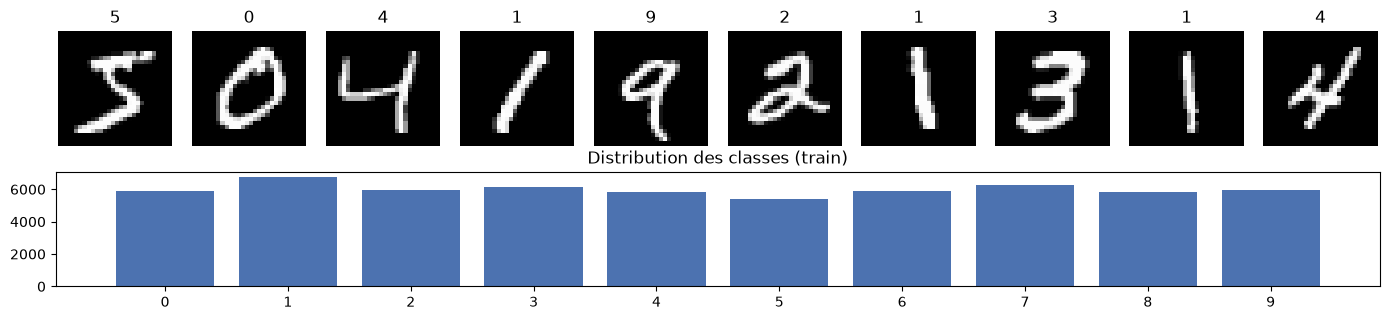

In [4]:
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081
to_tensor = lambda X: ((torch.from_numpy(X.copy()).float() / 255. - MNIST_MEAN) / MNIST_STD).unsqueeze(1)

train_ds = TensorDataset(to_tensor(X_train), torch.from_numpy(y_train.astype(np.int64)))
test_ds  = TensorDataset(to_tensor(X_test),  torch.from_numpy(y_test.astype(np.int64)))
pin = device.type == 'cuda'
train_loader = DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True, pin_memory=pin)
test_loader  = DataLoader(test_ds,  batch_size=512, shuffle=False, pin_memory=pin)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i, ax in enumerate(axes[0]):
    ax.imshow(X_train[i], cmap='gray'); ax.set_title(int(y_train[i])); ax.axis('off')
gs = plt.GridSpec(2, 1, figure=fig)
for ax in axes[1]: ax.remove()
ax = fig.add_subplot(gs[1])
ax.bar(range(10), np.bincount(y_train, minlength=10), color='#4C72B0')
ax.set_xticks(range(10)); ax.set_title('Distribution des classes (train)')
plt.tight_layout(); plt.savefig('figures/samples.png', dpi=110); plt.show()

### Fonctions communes d'entraînement / évaluation
Pour chaque modèle on mesure : **Accuracy**, **F1-score (macro)**, **Loss** (train/test), **temps d'entraînement**, temps d'inférence et nombre de paramètres.

In [5]:
LABELS = list(range(10))
count_params = lambda m: sum(p.numel() for p in m.parameters())

@torch.no_grad()
def evaluate(model, loader, criterion=nn.CrossEntropyLoss()):
    model.eval()
    tot_loss, preds, ys = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x)
        tot_loss += criterion(out.float(), y).item() * x.size(0)
        preds.append(out.argmax(1).cpu()); ys.append(y.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return tot_loss / len(ys), accuracy_score(ys, preds), f1_score(ys, preds, labels=LABELS, average='macro'), preds, ys

def fit(model, name, train_loader, test_loader, epochs, optimizer, scheduler=None):
    criterion = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'test_loss', 'test_acc']}
    train_time = 0.0
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time()
        run_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            run_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
        if scheduler is not None:
            scheduler.step()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        train_time += time.time() - t0
        te_loss, te_acc, te_f1, _, _ = evaluate(model, test_loader, criterion)
        hist['train_loss'].append(run_loss / n); hist['train_acc'].append(correct / n)
        hist['test_loss'].append(te_loss); hist['test_acc'].append(te_acc)
        print(f'[{name}] epoch {ep}/{epochs} | train loss {run_loss/n:.4f} acc {correct/n:.4f} '
              f'| test loss {te_loss:.4f} acc {te_acc:.4f} f1 {te_f1:.4f} | {train_time:.1f}s')
    t0 = time.time()
    te_loss, acc, f1, preds, ys = evaluate(model, test_loader, criterion)
    RESULTS[name] = dict(accuracy=acc, f1_macro=f1, train_loss=hist['train_loss'][-1], test_loss=te_loss,
                         train_time_s=train_time, inference_time_s=time.time() - t0,
                         params_M=count_params(model) / 1e6, epochs=epochs,
                         train_samples=len(train_loader.dataset))
    HISTORY[name] = hist
    return preds, ys

def plot_history(name):
    h = HISTORY[name]; ep = range(1, len(h['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(ep, h['train_loss'], 'o-', label='train'); ax[0].plot(ep, h['test_loss'], 's-', label='test')
    ax[0].set_title(f'{name} — Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
    ax[1].plot(ep, h['train_acc'], 'o-', label='train'); ax[1].plot(ep, h['test_acc'], 's-', label='test')
    ax[1].set_title(f'{name} — Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
    plt.tight_layout(); plt.savefig(f'figures/{name}_curves.png', dpi=110); plt.show()

def plot_cm(ys, preds, name):
    cm = confusion_matrix(ys, preds, labels=LABELS)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name} — matrice de confusion')
    plt.tight_layout(); plt.savefig(f'figures/{name}_cm.png', dpi=110); plt.show()

# Partie 1 — CNN Classifier

## 1.1 Architecture CNN

| Bloc | Couches | Sortie |
|---|---|---|
| Entrée | image 1×28×28 | 1×28×28 |
| Bloc 1 | Conv(1→32, k=3, s=1, p=1) + BN + ReLU → Conv(32→32, k=3, p=1) + BN + ReLU → MaxPool(2, s=2) → Dropout2d(0.1) | 32×14×14 |
| Bloc 2 | Conv(32→64, k=3, p=1) + BN + ReLU → Conv(64→64, k=3, p=1) + BN + ReLU → MaxPool(2, s=2) → Dropout2d(0.1) | 64×7×7 |
| Classifieur | Flatten → FC(3136→256) + ReLU → Dropout(0.3) → FC(256→10) | 10 |

**Hyper-paramètres :** kernels 3×3, padding 1 (conserve la taille), stride 1 pour les convolutions et 2 pour le pooling,
optimiseur **Adam** (lr = 1e-3), régularisation **weight decay 1e-4 + Dropout + BatchNorm**, scheduler StepLR (÷2 toutes les 2 epochs), loss CrossEntropy, batch 128.

In [6]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, p_drop=0.3):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2, stride=2), nn.Dropout2d(0.1))
        self.features = nn.Sequential(block(1, 32), block(32, 64))      # 28 -> 14 -> 7
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 256), nn.ReLU(inplace=True),
            nn.Dropout(p_drop), nn.Linear(256, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

cnn = CNN().to(device)
print(cnn)
print(f'Paramètres : {count_params(cnn):,}')

CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout2d(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running

[CNN] epoch 1/5 | train loss 0.1614 acc 0.9507 | test loss 0.0379 acc 0.9880 f1 0.9878 | 122.1s


[CNN] epoch 2/5 | train loss 0.0541 acc 0.9832 | test loss 0.0212 acc 0.9929 f1 0.9928 | 240.8s


[CNN] epoch 3/5 | train loss 0.0303 acc 0.9907 | test loss 0.0209 acc 0.9935 f1 0.9935 | 359.7s


[CNN] epoch 4/5 | train loss 0.0264 acc 0.9918 | test loss 0.0238 acc 0.9924 f1 0.9923 | 476.5s


[CNN] epoch 5/5 | train loss 0.0178 acc 0.9945 | test loss 0.0161 acc 0.9947 f1 0.9947 | 598.4s


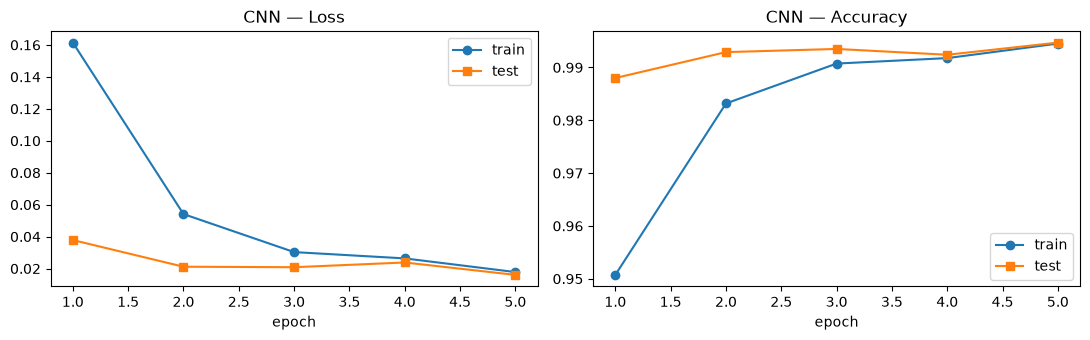

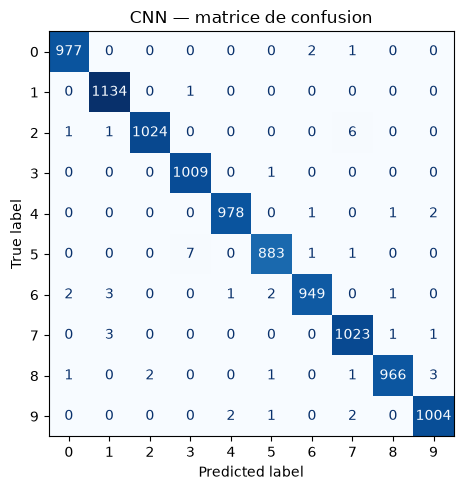

In [7]:
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.5)
cnn_preds, cnn_ys = fit(cnn, 'CNN', train_loader, test_loader, CFG['cnn_epochs'], opt, sched)
plot_history('CNN'); plot_cm(cnn_ys, cnn_preds, 'CNN')

## 1.2 Faster R-CNN

Faster R-CNN est un modèle de **détection d'objets** (backbone + Region Proposal Network + tête RoI qui prédit classe et boîte).
Pour l'appliquer à MNIST, on reformule la classification en détection :

* **cible** de chaque image = une seule boîte, la *bounding box* des pixels non nuls du chiffre, avec le label `chiffre + 1` (0 = fond) ;
* **prédiction de classe** = label de la détection ayant le meilleur score (aucune détection = erreur).

On utilise `fasterrcnn_mobilenet_v3_large_320_fpn` de torchvision (pré-entraîné sur COCO), dont on remplace la tête
`FastRCNNPredictor` par une tête à 11 classes. Les images 28×28 sont converties en 3 canaux et redimensionnées en interne à 128×128.
Optimiseur SGD (lr 0.01, momentum 0.9, weight decay 1e-4) avec warm-up linéaire puis décroissance cosinus.

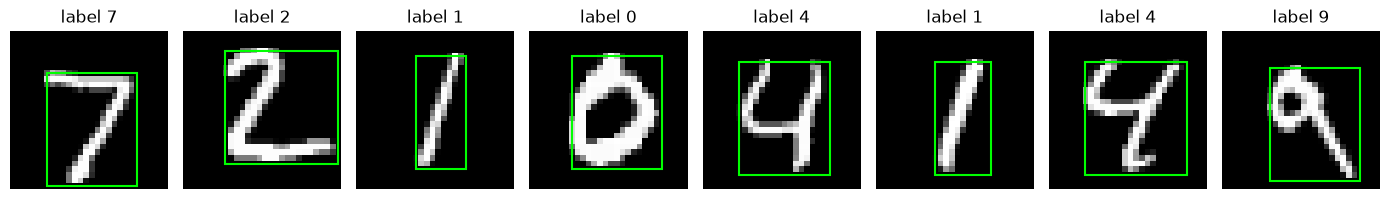

In [8]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

def compute_boxes(X):
    # boîte englobante [xmin, ymin, xmax, ymax] des pixels non nuls
    mask = X > 0
    rows, cols = mask.any(2), mask.any(1)
    H, W = X.shape[1:]
    ymin, ymax = rows.argmax(1), H - rows[:, ::-1].argmax(1)
    xmin, xmax = cols.argmax(1), W - cols[:, ::-1].argmax(1)
    return np.stack([xmin, ymin, xmax, ymax], 1).astype(np.float32)

class MNISTDetection(torch.utils.data.Dataset):
    def __init__(self, X, y, indices=None):
        self.idx = np.arange(len(X)) if indices is None else np.asarray(indices)
        self.X, self.y, self.boxes = X, y, compute_boxes(X)
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        img = torch.from_numpy(self.X[j].copy()).float().div(255.).unsqueeze(0).repeat(3, 1, 1)
        target = {'boxes': torch.from_numpy(self.boxes[j]).unsqueeze(0),
                  'labels': torch.tensor([int(self.y[j]) + 1], dtype=torch.int64)}
        return img, target

def det_collate(batch):
    return tuple(zip(*batch))

rng = np.random.default_rng(SEED)
fr_idx = None if CFG['frcnn_train_size'] is None else rng.choice(len(X_train), CFG['frcnn_train_size'], replace=False)
det_train = MNISTDetection(X_train, y_train, fr_idx)
det_test  = MNISTDetection(X_test, y_test)
det_train_loader = DataLoader(det_train, batch_size=CFG['frcnn_batch'], shuffle=True, collate_fn=det_collate)
det_test_loader  = DataLoader(det_test,  batch_size=64, shuffle=False, collate_fn=det_collate)

# visualisation des boîtes cibles
import matplotlib.patches as patches
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for ax, i in zip(axes, range(8)):
    img, t = det_test[i]; b = t['boxes'][0]
    ax.imshow(img[0], cmap='gray'); ax.axis('off'); ax.set_title(f"label {int(t['labels'][0]) - 1}")
    ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec='lime', lw=1.5))
plt.tight_layout(); plt.savefig('figures/frcnn_targets.png', dpi=110); plt.show()

In [9]:
S = CFG['frcnn_img_size']
frcnn = fasterrcnn_mobilenet_v3_large_320_fpn(weights=FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT,
                                             min_size=S, max_size=S)
in_features = frcnn.roi_heads.box_predictor.cls_score.in_features
frcnn.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=11)   # 10 chiffres + fond
frcnn.to(device)
print(f'Paramètres : {count_params(frcnn):,}')

Paramètres : 18,976,354


  step 0/625 loss 4.4519 loss_classifier=2.355 loss_box_reg=2.087 loss_objectness=0.008 loss_rpn_box_reg=0.001


  step 100/625 loss 1.2801 loss_classifier=0.400 loss_box_reg=0.875 loss_objectness=0.003 loss_rpn_box_reg=0.001


  step 200/625 loss 1.0106 loss_classifier=0.208 loss_box_reg=0.797 loss_objectness=0.004 loss_rpn_box_reg=0.002


  step 300/625 loss 0.9309 loss_classifier=0.213 loss_box_reg=0.712 loss_objectness=0.005 loss_rpn_box_reg=0.001


  step 400/625 loss 0.7520 loss_classifier=0.158 loss_box_reg=0.592 loss_objectness=0.002 loss_rpn_box_reg=0.001


...

  step 300/625 loss 0.2168 loss_classifier=0.064 loss_box_reg=0.152 loss_objectness=0.001 loss_rpn_box_reg=0.000


  step 400/625 loss 0.2183 loss_classifier=0.033 loss_box_reg=0.184 loss_objectness=0.001 loss_rpn_box_reg=0.000


  step 500/625 loss 0.2620 loss_classifier=0.117 loss_box_reg=0.144 loss_objectness=0.001 loss_rpn_box_reg=0.000


  step 600/625 loss 0.1362 loss_classifier=0.008 loss_box_reg=0.127 loss_objectness=0.001 loss_rpn_box_reg=0.000


[Faster R-CNN] epoch 2 | train loss 0.2854 | test loss 0.2001 acc 0.9927 f1 0.9927 | 1179.6s
Images sans détection : 0


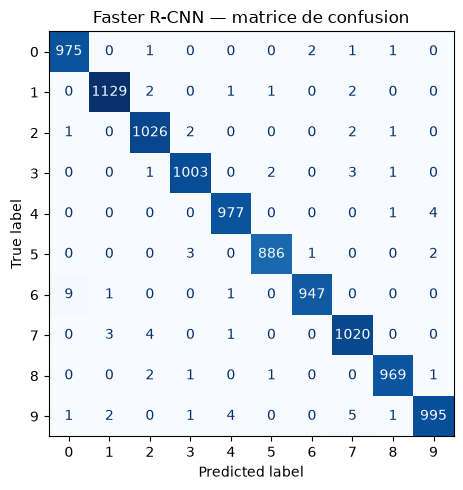

In [10]:
@torch.no_grad()
def frcnn_evaluate(model, loader):
    # loss de détection (mode train : le backbone utilise des FrozenBatchNorm, donc pas d'effet de bord)
    model.train(); tot_loss, n = 0.0, 0
    for imgs, targets in loader:
        imgs = [im.to(device) for im in imgs]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        tot_loss += sum(model(imgs, targets).values()).item() * len(imgs); n += len(imgs)
    # prédictions : classe de la détection de meilleur score
    model.eval(); preds, ys = [], []; t0 = time.time()
    for imgs, targets in loader:
        outs = model([im.to(device) for im in imgs])
        for o, t in zip(outs, targets):
            preds.append(int(o['labels'][0]) - 1 if len(o['labels']) else -1)
            ys.append(int(t['labels'][0]) - 1)
    pred_time = time.time() - t0
    preds, ys = np.array(preds), np.array(ys)
    return tot_loss / n, accuracy_score(ys, preds), f1_score(ys, preds, labels=LABELS, average='macro'), preds, ys, pred_time

params = [p for p in frcnn.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=0.01, momentum=0.9, weight_decay=1e-4)
total_steps, warmup = CFG['frcnn_epochs'] * len(det_train_loader), 200
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1.0, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * s / total_steps)))

hist = {k: [] for k in ['train_loss', 'train_acc', 'test_loss', 'test_acc']}
train_time = 0.0
for ep in range(1, CFG['frcnn_epochs'] + 1):
    frcnn.train(); t0 = time.time(); run_loss, n = 0.0, 0
    for step, (imgs, targets) in enumerate(det_train_loader):
        imgs = [im.to(device) for im in imgs]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = frcnn(imgs, targets)
        loss = sum(loss_dict.values())
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        run_loss += loss.item() * len(imgs); n += len(imgs)
        if step % 100 == 0:
            print(f'  step {step}/{len(det_train_loader)} loss {loss.item():.4f} ' +
                  ' '.join(f'{k}={v.item():.3f}' for k, v in loss_dict.items()))
    if device.type == 'cuda':
        torch.cuda.synchronize()
    train_time += time.time() - t0
    te_loss, te_acc, te_f1, fr_preds, fr_ys, infer_time = frcnn_evaluate(frcnn, det_test_loader)
    hist['train_loss'].append(run_loss / n); hist['train_acc'].append(float('nan'))
    hist['test_loss'].append(te_loss); hist['test_acc'].append(te_acc)
    print(f'[Faster R-CNN] epoch {ep} | train loss {run_loss/n:.4f} | test loss {te_loss:.4f} '
          f'acc {te_acc:.4f} f1 {te_f1:.4f} | {train_time:.1f}s')

RESULTS['Faster R-CNN'] = dict(accuracy=te_acc, f1_macro=te_f1, train_loss=hist['train_loss'][-1], test_loss=te_loss,
                               train_time_s=train_time, inference_time_s=infer_time,
                               params_M=count_params(frcnn) / 1e6, epochs=CFG['frcnn_epochs'],
                               train_samples=len(det_train))
HISTORY['Faster R-CNN'] = hist
print('Images sans détection :', int((fr_preds == -1).sum()))
plot_cm(fr_ys, fr_preds, 'Faster R-CNN')

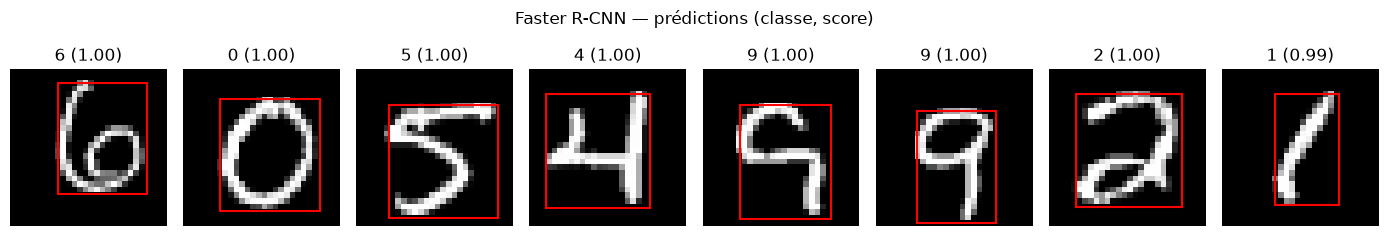

In [11]:
frcnn.eval()
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
with torch.no_grad():
    for ax, i in zip(axes, range(100, 108)):
        img, t = det_test[i]
        o = frcnn([img.to(device)])[0]
        ax.imshow(img[0], cmap='gray'); ax.axis('off')
        if len(o['boxes']):
            b = o['boxes'][0].cpu()
            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec='red', lw=1.5))
            ax.set_title(f"{int(o['labels'][0]) - 1} ({o['scores'][0]:.2f})")
plt.suptitle('Faster R-CNN — prédictions (classe, score)', y=1.05)
plt.tight_layout(); plt.savefig('figures/frcnn_predictions.png', dpi=110, bbox_inches='tight'); plt.show()

## 1.3 Comparaison CNN vs Faster R-CNN

In [12]:
def results_table(names=None):
    df = pd.DataFrame(RESULTS).T
    if names is not None:
        df = df.loc[names]
    return df[['accuracy', 'f1_macro', 'train_loss', 'test_loss', 'train_time_s', 'inference_time_s',
               'params_M', 'epochs', 'train_samples']].astype(float).round(4)

results_table(['CNN', 'Faster R-CNN'])

,accuracy,f1_macro,train_loss,test_loss,train_time_s,inference_time_s,params_M,epochs,train_samples
CNN,0.9947,0.9947,0.0178,0.0161,598.4077,6.5276,0.8710,5.0,60000.0
Faster R-CNN,0.9927,0.9927,0.2854,0.2001,1179.5628,146.4819,18.9764,2.0,10000.0


> Remarque : la loss du Faster R-CNN est la **somme des 4 losses de détection** (classification RPN, régression RPN,
> classification RoI, régression des boîtes) ; elle n'est pas directement comparable à la CrossEntropy du CNN.

## 1.4 Fine-tuning de modèles pré-entraînés : VGG16 et AlexNet

Les deux réseaux sont pré-entraînés sur ImageNet (entrée RGB normalisée). On adapte MNIST via un module `ImageNetAdapter` :
dé-normalisation MNIST → redimensionnement bilinéaire → duplication en 3 canaux → normalisation ImageNet.
La dernière couche `classifier[6]` (4096 → 1000) est remplacée par une couche 4096 → 10, puis **tout le réseau est fine-tuné**
(Adam, lr = 1e-4, weight decay 1e-4).

In [13]:
from torchvision.models import vgg16, VGG16_Weights, alexnet, AlexNet_Weights

class ImageNetAdapter(nn.Module):
    def __init__(self, backbone, size):
        super().__init__()
        self.backbone, self.size = backbone, size
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        x = x * MNIST_STD + MNIST_MEAN                                   # retour dans [0, 1]
        x = F.interpolate(x, size=(self.size, self.size), mode='bilinear', align_corners=False)
        x = x.repeat(1, 3, 1, 1)
        return self.backbone((x - self.mean) / self.std)

tl_idx = np.arange(len(train_ds)) if CFG['tl_train_size'] is None else \
         np.random.default_rng(SEED).choice(len(train_ds), CFG['tl_train_size'], replace=False)
tl_train_loader = DataLoader(Subset(train_ds, tl_idx), batch_size=CFG['tl_batch'], shuffle=True, pin_memory=pin)
tl_test_loader  = DataLoader(test_ds, batch_size=256, shuffle=False, pin_memory=pin)

VGG16 — paramètres : 134,301,514


[VGG16] epoch 1/2 | train loss 0.2686 acc 0.9143 | test loss 0.1067 acc 0.9707 f1 0.9705 | 839.0s


[VGG16] epoch 2/2 | train loss 0.0539 acc 0.9847 | test loss 0.1023 acc 0.9763 f1 0.9760 | 8687.6s


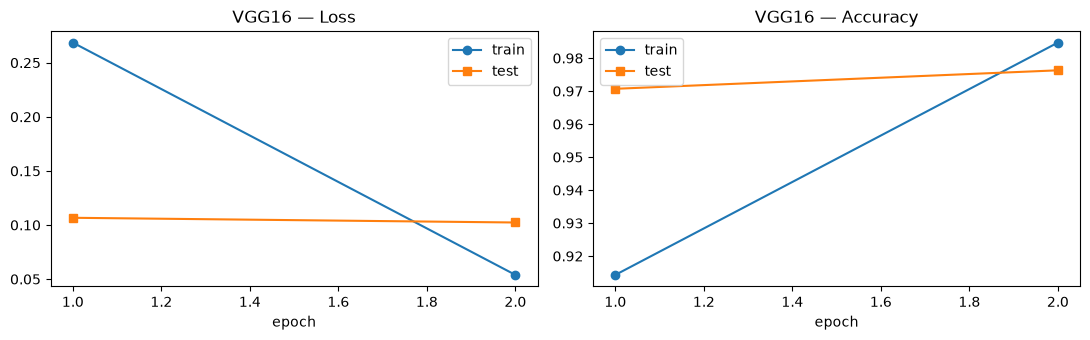

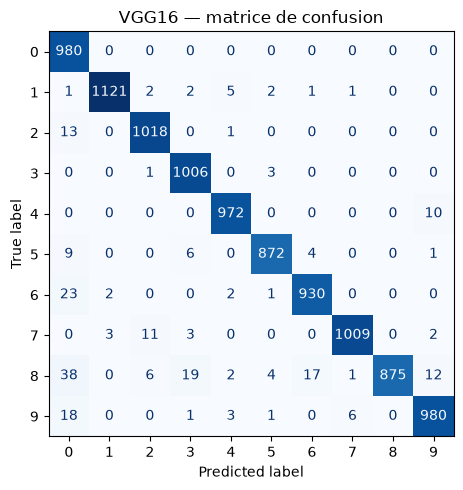

In [14]:
vgg = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
vgg.classifier[6] = nn.Linear(4096, 10)
vgg = ImageNetAdapter(vgg, CFG['tl_img_size']).to(device)
print(f'VGG16 — paramètres : {count_params(vgg):,}')

opt = torch.optim.Adam(vgg.parameters(), lr=1e-4, weight_decay=1e-4)
vgg_preds, vgg_ys = fit(vgg, 'VGG16', tl_train_loader, tl_test_loader, CFG['tl_epochs'], opt)
plot_history('VGG16'); plot_cm(vgg_ys, vgg_preds, 'VGG16')
del vgg
if device.type == 'cuda': torch.cuda.empty_cache()

AlexNet — paramètres : 57,044,810


[AlexNet] epoch 1/2 | train loss 0.3414 acc 0.8882 | test loss 0.0982 acc 0.9697 f1 0.9693 | 122.3s


[AlexNet] epoch 2/2 | train loss 0.0749 acc 0.9772 | test loss 0.0777 acc 0.9760 f1 0.9759 | 240.4s


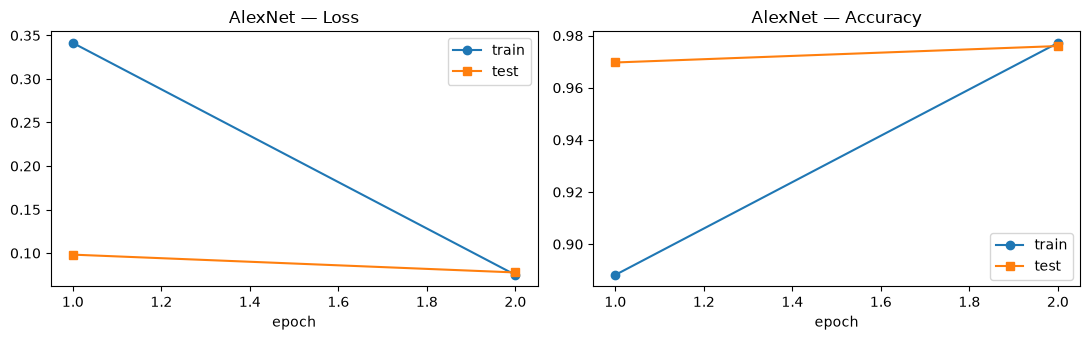

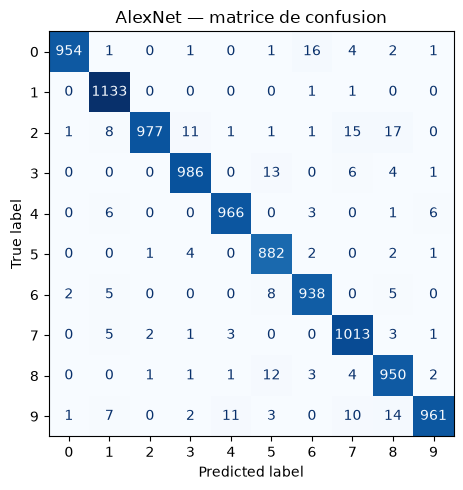

In [15]:
alex = alexnet(weights=AlexNet_Weights.IMAGENET1K_V1)
alex.classifier[6] = nn.Linear(4096, 10)
alex = ImageNetAdapter(alex, CFG['tl_img_size']).to(device)
print(f'AlexNet — paramètres : {count_params(alex):,}')

opt = torch.optim.Adam(alex.parameters(), lr=1e-4, weight_decay=1e-4)
alex_preds, alex_ys = fit(alex, 'AlexNet', tl_train_loader, tl_test_loader, CFG['tl_epochs'], opt)
plot_history('AlexNet'); plot_cm(alex_ys, alex_preds, 'AlexNet')

### Comparaison CNN / Faster R-CNN / VGG16 / AlexNet

In [16]:
results_table(['CNN', 'Faster R-CNN', 'VGG16', 'AlexNet'])

,accuracy,f1_macro,train_loss,test_loss,train_time_s,inference_time_s,params_M,epochs,train_samples
CNN,0.9947,0.9947,0.0178,0.0161,598.4077,6.5276,0.8710,5.0,60000.0
Faster R-CNN,0.9927,0.9927,0.2854,0.2001,1179.5628,146.4819,18.9764,2.0,10000.0
VGG16,0.9763,0.9760,0.0539,0.1023,8687.5920,220.1120,134.3015,2.0,10000.0
AlexNet,0.9760,0.9759,0.0749,0.0777,240.4393,17.1909,57.0448,2.0,10000.0


### Conclusion de la partie 1

| Modèle | Accuracy | F1 macro | Test loss | Temps d'entraînement | ms / image / epoch | Paramètres |
|---|---|---|---|---|---|---|
| **CNN** | **99.47 %** | **0.9947** | 0.016 | 598 s (5 ep., 60k) | **2.0** | 0.87 M |
| Faster R-CNN | 99.27 % | 0.9927 | 0.200* | 1 180 s (2 ep., 10k) | 59 | 19.0 M |
| VGG16 | 97.63 % | 0.9760 | 0.102 | 8 688 s** (2 ep., 10k) | 84** | 134.3 M |
| AlexNet | 97.60 % | 0.9759 | 0.078 | 240 s (2 ep., 10k) | 12 | 57.0 M |

\* somme des losses de détection (non comparable à la CrossEntropy) — \*\* l'epoch 2 de VGG16 a été ralentie par la mise en veille de la machine ; l'epoch 1 (839 s, soit 84 ms/image) est représentative.

* **CNN vs Faster R-CNN** : les deux atteignent > 99 %, mais le CNN est meilleur (+0.2 pt), ~30× plus rapide par image en entraînement, ~22× plus rapide en inférence et 22× plus léger. Faster R-CNN est conçu pour *localiser* plusieurs objets ; sur MNIST (un seul chiffre centré) sa complexité (RPN, RoI pooling, 4 losses) est inutile — son seul avantage est de fournir la boîte englobante en plus de la classe.
* **VGG16 / AlexNet** : le fine-tuning donne ~97.6 %, **moins bien que le petit CNN**. Raisons : domaine très différent d'ImageNet (chiffres 28×28 en niveaux de gris agrandis en 64×64 vs photos couleur), seulement 10k images et 2 epochs, et des réseaux énormes (57–134 M de paramètres) qui commencent à sur-apprendre (VGG16 : 98.5 % en train vs 97.6 % en test, test loss 2× la train loss). Avec plus de données, des images 224×224 et plus d'epochs (sur GPU), leurs scores augmenteraient, mais pour un coût sans commune mesure.
* **Conclusion** : pour un dataset simple, petit en résolution et abondant comme MNIST, un **CNN dédié et léger** offre le meilleur compromis précision / coût. Le transfer learning est surtout rentable quand les données sont rares et proches du domaine de pré-entraînement.

# Partie 2 — Vision Transformer (ViT) from scratch

Implémentation fidèle au tutoriel *« Vision Transformers from Scratch (PyTorch): A step-by-step guide »* (B. Pulfer, Medium),
basé sur Dosovitskiy et al., *An Image is Worth 16x16 Words* (2020) :

1. **Patchify** : l'image 1×28×28 est découpée en 7×7 = 49 patches de 4×4 (vecteurs de 16 valeurs) ;
2. **Linear mapping** : chaque patch est projeté en un token de dimension `hidden_d` ;
3. **Class token** appris, ajouté en tête de séquence (50 tokens) ;
4. **Positional embedding** sinusoïdal ajouté aux tokens ;
5. **Encoder blocks** : `x + MSA(LN(x))` puis `x + MLP(LN(x))` (MLP : Linear → GELU → Linear, ratio 4) ;
6. **Tête de classification** sur le class token.

Modifications par rapport au tutoriel (sans changer l'architecture) :
* `patchify` et la Multi-Head Self-Attention sont **vectorisés** (le tutoriel boucle en Python sur les images et les séquences, très lent sur GPU) — l'équivalence est vérifiée ci-dessous ;
* la tête renvoie des **logits** (le tutoriel applique un `Softmax` avant `CrossEntropyLoss`, qui applique déjà un log-softmax) ;
* modèle un peu plus large (`hidden_d=64`, 4 têtes, 4 blocs au lieu de 8 / 2 / 2) et AdamW + cosine, pour un résultat comparable aux CNN.

patchify vectorisé == tutoriel : True


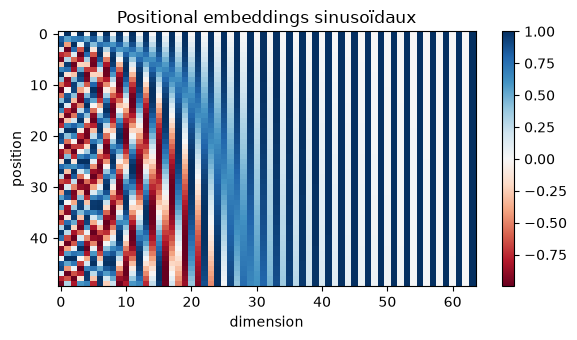

In [17]:
def patchify_loop(images, n_patches):
    # version du tutoriel (boucles) — utilisée seulement pour vérifier la version vectorisée
    n, c, h, w = images.shape
    patches = torch.zeros(n, n_patches ** 2, h * w * c // n_patches ** 2)
    patch_size = h // n_patches
    for idx, image in enumerate(images):
        for i in range(n_patches):
            for j in range(n_patches):
                patch = image[:, i * patch_size: (i + 1) * patch_size, j * patch_size: (j + 1) * patch_size]
                patches[idx, i * n_patches + j] = patch.flatten()
    return patches

def patchify(images, n_patches):
    n, c, h, w = images.shape
    p = h // n_patches
    patches = images.unfold(2, p, p).unfold(3, p, p)                    # (n, c, np, np, p, p)
    return patches.permute(0, 2, 3, 1, 4, 5).reshape(n, n_patches ** 2, c * p * p)

def get_positional_embeddings(sequence_length, d):
    result = torch.ones(sequence_length, d)
    for i in range(sequence_length):
        for j in range(d):
            result[i][j] = np.sin(i / (10000 ** (j / d))) if j % 2 == 0 else np.cos(i / (10000 ** ((j - 1) / d)))
    return result

x_chk = train_ds.tensors[0][:4]
print('patchify vectorisé == tutoriel :', torch.allclose(patchify(x_chk, 7), patchify_loop(x_chk, 7)))

pe = get_positional_embeddings(50, 64)
plt.figure(figsize=(6, 3.5)); plt.imshow(pe, cmap='RdBu', aspect='auto'); plt.colorbar()
plt.xlabel('dimension'); plt.ylabel('position'); plt.title('Positional embeddings sinusoïdaux')
plt.tight_layout(); plt.savefig('figures/vit_pos_embeddings.png', dpi=110); plt.show()

In [18]:
class MyMSA(nn.Module):
    def __init__(self, d, n_heads=2):
        super().__init__()
        assert d % n_heads == 0, f"Can't divide dimension {d} into {n_heads} heads"
        self.d, self.n_heads, self.d_head = d, n_heads, d // n_heads
        self.q_mappings = nn.ModuleList([nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)])
        self.k_mappings = nn.ModuleList([nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)])
        self.v_mappings = nn.ModuleList([nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)])
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, sequences):
        # sequences : (N, seq_length, d) -> chaque tête traite sa tranche de d_head dimensions
        result = []
        for head in range(self.n_heads):
            seq = sequences[..., head * self.d_head: (head + 1) * self.d_head]
            q, k, v = self.q_mappings[head](seq), self.k_mappings[head](seq), self.v_mappings[head](seq)
            attention = self.softmax(q @ k.transpose(-2, -1) / (self.d_head ** 0.5))
            result.append(attention @ v)
        return torch.cat(result, dim=-1)

class MyViTBlock(nn.Module):
    def __init__(self, hidden_d, n_heads, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden_d)
        self.mhsa = MyMSA(hidden_d, n_heads)
        self.norm2 = nn.LayerNorm(hidden_d)
        self.mlp = nn.Sequential(nn.Linear(hidden_d, mlp_ratio * hidden_d), nn.GELU(),
                                 nn.Linear(mlp_ratio * hidden_d, hidden_d))

    def forward(self, x):
        out = x + self.mhsa(self.norm1(x))
        return out + self.mlp(self.norm2(out))

class MyViT(nn.Module):
    def __init__(self, chw, n_patches=7, n_blocks=2, hidden_d=8, n_heads=2, out_d=10):
        super().__init__()
        self.chw, self.n_patches, self.hidden_d = chw, n_patches, hidden_d
        assert chw[1] % n_patches == 0 and chw[2] % n_patches == 0, 'Input shape not entirely divisible by number of patches'
        self.patch_size = (chw[1] // n_patches, chw[2] // n_patches)
        # 1) linear mapper
        self.input_d = chw[0] * self.patch_size[0] * self.patch_size[1]
        self.linear_mapper = nn.Linear(self.input_d, hidden_d)
        # 2) class token
        self.class_token = nn.Parameter(torch.rand(1, hidden_d))
        # 3) positional embedding (non appris)
        self.register_buffer('positional_embeddings', get_positional_embeddings(n_patches ** 2 + 1, hidden_d),
                             persistent=False)
        # 4) transformer encoder blocks
        self.blocks = nn.ModuleList([MyViTBlock(hidden_d, n_heads) for _ in range(n_blocks)])
        # 5) classification MLP (logits)
        self.mlp = nn.Linear(hidden_d, out_d)

    def forward(self, images):
        n = images.shape[0]
        tokens = self.linear_mapper(patchify(images, self.n_patches))
        tokens = torch.cat((self.class_token.expand(n, 1, -1), tokens), dim=1)
        out = tokens + self.positional_embeddings.unsqueeze(0)
        for block in self.blocks:
            out = block(out)
        return self.mlp(out[:, 0])

vit = MyViT((1, 28, 28), n_patches=7, n_blocks=4, hidden_d=64, n_heads=4, out_d=10).to(device)
print(vit)
print(f'Paramètres : {count_params(vit):,}')

MyViT(
  (linear_mapper): Linear(in_features=16, out_features=64, bias=True)
  (blocks): ModuleList(
    (0-3): 4 x MyViTBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (mhsa): MyMSA(
        (q_mappings): ModuleList(
          (0-3): 4 x Linear(in_features=16, out_features=16, bias=True)
        )
        (k_mappings): ModuleList(
          (0-3): 4 x Linear(in_features=16, out_features=16, bias=True)
        )
        (v_mappings): ModuleList(
          (0-3): 4 x Linear(in_features=16, out_features=16, bias=True)
        )
        (softmax): Softmax(dim=-1)
      )
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=256, out_features=64, bias=True)
      )
    )
  )
  (mlp): Linear(in_features=64, out_features=10, bias=True)
)
Paramètres : 148,234


[ViT] epoch 1/10 | train loss 0.7195 acc 0.7464 | test loss 0.2240 acc 0.9288 f1 0.9279 | 96.1s


[ViT] epoch 2/10 | train loss 0.1912 acc 0.9405 | test loss 0.1564 acc 0.9467 f1 0.9464 | 189.1s


[ViT] epoch 3/10 | train loss 0.1282 acc 0.9598 | test loss 0.1059 acc 0.9659 f1 0.9655 | 278.2s


[ViT] epoch 4/10 | train loss 0.0923 acc 0.9702 | test loss 0.0876 acc 0.9737 f1 0.9735 | 370.9s


[ViT] epoch 5/10 | train loss 0.0716 acc 0.9771 | test loss 0.0903 acc 0.9723 f1 0.9721 | 462.1s


[ViT] epoch 6/10 | train loss 0.0533 acc 0.9828 | test loss 0.0667 acc 0.9775 f1 0.9773 | 523.6s


[ViT] epoch 7/10 | train loss 0.0393 acc 0.9874 | test loss 0.0598 acc 0.9803 f1 0.9801 | 581.9s


[ViT] epoch 8/10 | train loss 0.0274 acc 0.9913 | test loss 0.0588 acc 0.9821 f1 0.9820 | 637.9s


[ViT] epoch 9/10 | train loss 0.0187 acc 0.9948 | test loss 0.0523 acc 0.9833 f1 0.9831 | 693.3s


[ViT] epoch 10/10 | train loss 0.0138 acc 0.9963 | test loss 0.0518 acc 0.9839 f1 0.9838 | 747.0s


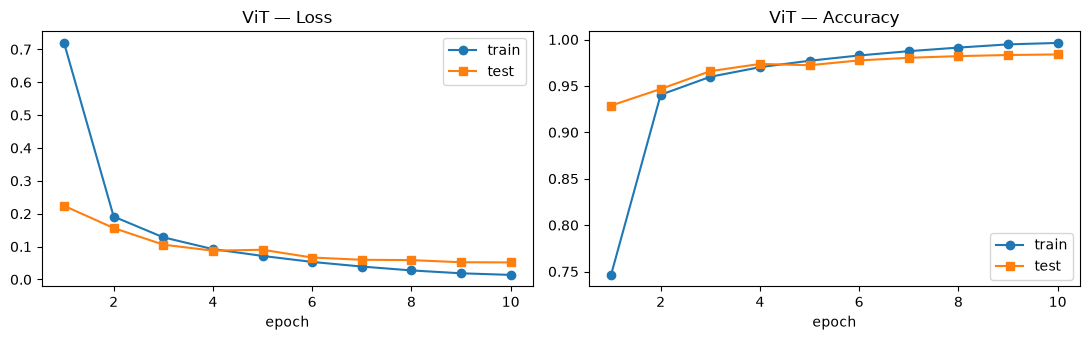

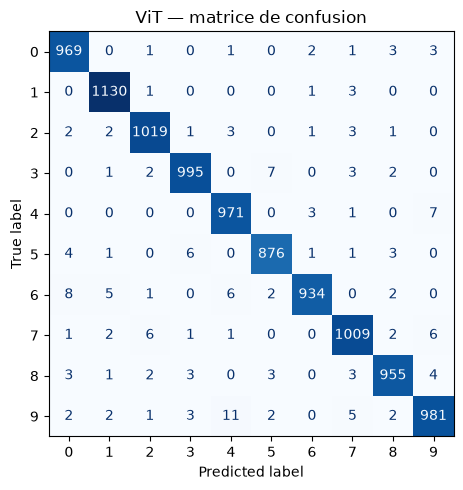

In [19]:
opt = torch.optim.AdamW(vit.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['vit_epochs'])
vit_preds, vit_ys = fit(vit, 'ViT', train_loader, test_loader, CFG['vit_epochs'], opt, sched)
plot_history('ViT'); plot_cm(vit_ys, vit_preds, 'ViT')

## 2.2 Comparaison globale de tous les modèles

In [20]:
df = results_table(['CNN', 'Faster R-CNN', 'VGG16', 'AlexNet', 'ViT'])
df.to_csv('results.csv')
with open('results.json', 'w') as f:
    json.dump({'device': str(device), 'config': CFG, 'results': RESULTS}, f, indent=2)
df

,accuracy,f1_macro,train_loss,test_loss,train_time_s,inference_time_s,params_M,epochs,train_samples
CNN,0.9947,0.9947,0.0178,0.0161,598.4077,6.5276,0.8710,5.0,60000.0
Faster R-CNN,0.9927,0.9927,0.2854,0.2001,1179.5628,146.4819,18.9764,2.0,10000.0
VGG16,0.9763,0.9760,0.0539,0.1023,8687.5920,220.1120,134.3015,2.0,10000.0
AlexNet,0.9760,0.9759,0.0749,0.0777,240.4393,17.1909,57.0448,2.0,10000.0
ViT,0.9839,0.9838,0.0138,0.0518,747.0358,4.0994,0.1482,10.0,60000.0


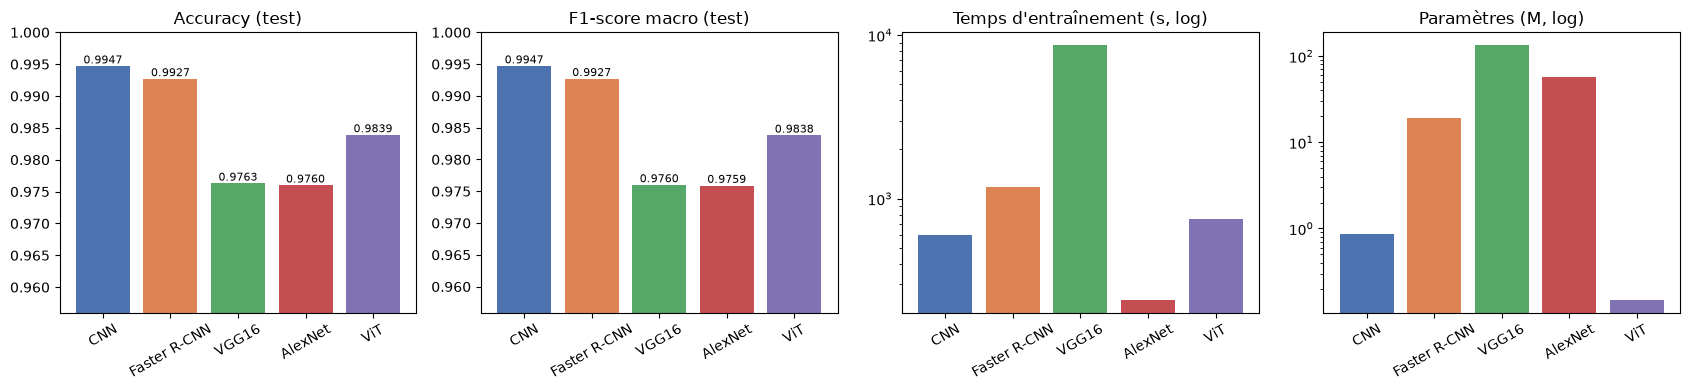

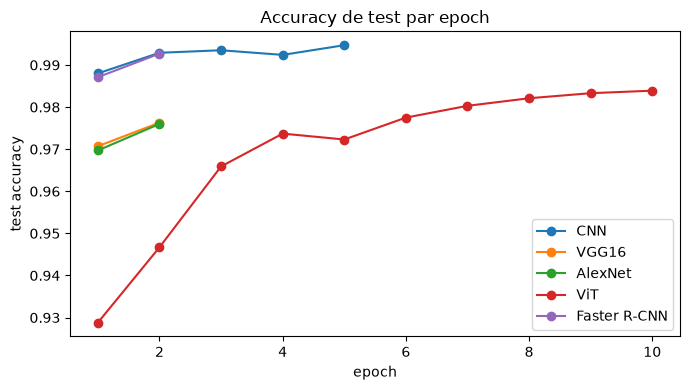

In [21]:
names = list(df.index)
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (col, title) in zip(axes, [('accuracy', 'Accuracy (test)'), ('f1_macro', 'F1-score macro (test)'),
                                   ('train_time_s', "Temps d'entraînement (s, log)"), ('params_M', 'Paramètres (M, log)')]):
    ax.bar(names, df[col], color=colors)
    ax.set_title(title); ax.tick_params(axis='x', rotation=30)
    if col in ('accuracy', 'f1_macro'):
        ax.set_ylim(max(0, df[col].min() - 0.02), 1.0)
        for i, v in enumerate(df[col]): ax.text(i, v, f'{v:.4f}', ha='center', va='bottom', fontsize=8)
    else:
        ax.set_yscale('log')
plt.tight_layout(); plt.savefig('figures/comparison.png', dpi=110); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for n in ['CNN', 'VGG16', 'AlexNet', 'ViT', 'Faster R-CNN']:
    ax.plot(range(1, len(HISTORY[n]['test_acc']) + 1), HISTORY[n]['test_acc'], 'o-', label=n)
ax.set_xlabel('epoch'); ax.set_ylabel('test accuracy'); ax.set_title('Accuracy de test par epoch'); ax.legend()
plt.tight_layout(); plt.savefig('figures/test_acc_epochs.png', dpi=110); plt.show()

## Interprétation & synthèse

### Résultats du ViT (partie 2)
Le ViT from scratch atteint **98.39 % d'accuracy (F1 = 0.9838)** avec seulement **148 k paramètres** (le plus petit modèle du lab) :

* il dépasse VGG16 et AlexNet fine-tunés, mais reste **sous le CNN (99.47 %)** et Faster R-CNN (99.27 %) ;
* sa courbe d'accuracy de test monte encore à chaque epoch (92.9 % → 98.4 %), et l'écart train/test (99.6 % / 98.4 %) montre un début de sur-apprentissage : il lui faudrait plus d'epochs, de l'augmentation de données ou plus de régularisation ;
* le CNN possède des **biais inductifs** (localité, invariance par translation, partage de poids) parfaitement adaptés aux images ; le ViT doit **apprendre** ces relations spatiales via l'attention, ce qui demande plus de données / d'epochs — c'est pourquoi les ViT brillent surtout lorsqu'ils sont pré-entraînés sur de très grands datasets ;
* côté coût, une epoch de ViT (~75 s) est plus rapide que celle du CNN (~120 s) grâce à sa petite taille, mais il lui faut 2× plus d'epochs pour converger, d'où un temps total plus long (747 s vs 598 s) ; en inférence il est le plus rapide (4.1 s pour 10 000 images). Son coût croît toutefois de façon quadratique avec le nombre de patches (attention sur 50 tokens ici).

### Classement global

| Rang | Modèle | Accuracy | Paramètres | Verdict |
|---|---|---|---|---|
| 1 | CNN | 99.47 % | 0.87 M | meilleur compromis |
| 2 | Faster R-CNN | 99.27 % | 19.0 M | précis mais lourd ; fournit aussi la boîte |
| 3 | ViT | 98.39 % | 0.15 M | très compact, a besoin de plus d'entraînement |
| 4 | VGG16 | 97.63 % | 134.3 M | coûteux, domaine éloigné d'ImageNet |
| 5 | AlexNet | 97.60 % | 57.0 M | rapide mais peu adapté |

### Synthèse — ce que j'ai appris
* **PyTorch** : construire des modèles avec `nn.Module`/`nn.Sequential`, écrire des boucles d'entraînement et d'évaluation génériques, utiliser `Dataset`/`DataLoader`, optimiseurs (Adam, AdamW, SGD), schedulers (StepLR, cosine, warm-up) et l'exécution sur GPU (`.to(device)`, mixed precision `torch.autocast`).
* **CNN** : rôle des convolutions, du padding, du stride, du pooling, de la BatchNorm et du Dropout ; un petit CNN bien régularisé suffit à dépasser 99.4 % sur MNIST.
* **Détection (Faster R-CNN)** : backbone + RPN + RoI heads ; reformuler un problème de classification en détection (génération des boîtes cibles), remplacer la tête de prédiction d'un modèle pré-entraîné.
* **Transfer learning** : adapter l'entrée (3 canaux, taille, normalisation ImageNet), remplacer la dernière couche, fine-tuner ; et surtout que le transfer learning n'est pas toujours gagnant quand le domaine diffère beaucoup.
* **Vision Transformer** : patchify, linear embedding, class token, positional embeddings sinusoïdaux, Multi-Head Self-Attention, blocs encodeur avec LayerNorm et connexions résiduelles ; et le rôle des biais inductifs CNN vs Transformer.
* **Évaluation** : comparer des modèles sur plusieurs axes (accuracy, F1, loss, temps d'entraînement/inférence, taille) et non sur la seule accuracy.